# Pipeline NLLB + LoRA — Traducteur multilingue Français · Anglais · Éwé

**Projet de groupe — GR02** · Master 1 IA-BD EPL S2 (Informatique et Gestion de données)

| Membres du groupe GR02 |
|---|
| AZIGLOSSOU Judith Gracia |
| NAPO NISSAO Rafia |
| WOGLO Koffi Boris Gilbride |
| PIO Sikirou Afeez Prince Cyrille |
| KOMBATE Gountande |

Sujet : *Traducteur Multilingue (Français, Anglais, Éwé) avec Reconnaissance Vocale* — proposé par Mme GBEDEVI.

---

Ce **notebook unique** regroupe tout le pipeline de traduction automatique demandé par le cahier des charges :

1. **Diagnostic GPU** — vérifier que CUDA est disponible avant l'entraînement.
2. **Préparation (optionnelle) du corpus** — import OPUS + Hugging Face, alignement, nettoyage.
3. **Exploration du corpus** — volumes par direction, contrôle du biais religieux.
4. **Fine-tuning LoRA** de `facebook/nllb-200-distilled-600M` sur les 6 directions (fr↔en, fr↔ewe, en↔ewe).
5. **Suivi des pertes** (train / validation) et courbes.
6. **Évaluation finale BLEU / chrF** par direction.
7. **Démo de traduction** sur l'adapter entraîné.

L'adapter LoRA final est sauvegardé dans `models/nllb-ewe-lora`, avec les rapports d'évaluation et le journal d'entraînement.


## 0. Mode d'emploi

1. Lancez ce notebook avec le kernel Python du projet: `.venv`.
2. Executez d'abord le diagnostic GPU. Si `torch.cuda.is_available()` vaut `False`, corrigez PyTorch CUDA avant de continuer.
3. Gardez `MODE = "smoke"` pour verifier que tout marche rapidement.
4. Passez a `MODE = "full"` pour le vrai fine-tuning.

Le notebook sauvegarde l'adapter LoRA dans `models/nllb-ewe-lora` et les rapports dans le meme dossier.

In [ ]:
from pathlib import Path
import os
import sys
import subprocess
import time
import json

# --- Chemins du projet --------------------------------------------------------
PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
os.chdir(PROJECT_ROOT)
sys.path.insert(0, str(PROJECT_ROOT / "src"))

DATA_DIR = PROJECT_ROOT / "data" / "processed" / "nllb"
TRAIN_CSV = DATA_DIR / "nllb_train.csv"
VALID_CSV = DATA_DIR / "nllb_valid.csv"
TEST_CSV = DATA_DIR / "nllb_test.csv"
SUMMARY_CSV = DATA_DIR / "nllb_summary.csv"

MODEL_NAME = "facebook/nllb-200-distilled-600M"
OUTPUT_DIR = PROJECT_ROOT / "models" / "nllb-ewe-lora"

# --- Configuration de l'exécution --------------------------------------------
# MODE = "smoke" : test rapide de bout en bout (quelques minutes) pour vérifier
#                  que tout le pipeline fonctionne.
# MODE = "full"  : vrai fine-tuning sur l'ensemble du corpus.
MODE = "full"
REQUIRE_CUDA = True          # bloque l'entraînement si CUDA est indisponible
RUN_DATA_PREPARATION = False  # True pour (re)générer le dataset depuis les scripts

# Les hyperparamètres s'adaptent automatiquement au MODE choisi.
IS_SMOKE = MODE == "smoke"
MAX_TRAIN_SAMPLES = 512 if IS_SMOKE else 60000
MAX_VALID_SAMPLES = 128 if IS_SMOKE else 6000
MAX_EVAL_PER_DIRECTION = 20 if IS_SMOKE else 100
EPOCHS = 0.05 if IS_SMOKE else 1.0
TRAIN_BATCH_SIZE = 2
EVAL_BATCH_SIZE = 2
GRADIENT_ACCUMULATION_STEPS = 4
MAX_SOURCE_LENGTH = 128
MAX_TARGET_LENGTH = 128
LEARNING_RATE = 2e-4

print("Projet:", PROJECT_ROOT)
print("Mode:", MODE, "| échantillon train:", MAX_TRAIN_SAMPLES, "| epochs:", EPOCHS)
print("Sortie LoRA:", OUTPUT_DIR)


## 1. Diagnostic GPU

Si Windows voit le GPU mais que cette cellule affiche `cuda_available = False`, le probleme vient presque toujours d'une installation PyTorch CPU-only.

In [2]:
import torch

print("torch:", torch.__version__)
print("cuda_available:", torch.cuda.is_available())
print("torch_cuda_runtime:", torch.version.cuda)
print("device_count:", torch.cuda.device_count())
if torch.cuda.is_available():
    print("device_name:", torch.cuda.get_device_name(0))
    print("bf16_supported:", torch.cuda.is_bf16_supported())
    torch.set_float32_matmul_precision("high")
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True
else:
    print("Commande conseillee:")
    print("python -m pip uninstall -y torch torchvision torchaudio")
    print("python -m pip install torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu128")

if REQUIRE_CUDA and not torch.cuda.is_available():
    raise RuntimeError("CUDA indisponible dans cet environnement Python. Installez PyTorch CUDA avant l'entrainement.")

torch: 2.11.0+cu128
cuda_available: True
torch_cuda_runtime: 12.8
device_count: 1
device_name: NVIDIA GeForce RTX 5080 Laptop GPU
bf16_supported: True


## 2. Preparation optionnelle du dataset

Cette cellule reste optionnelle. Si `data/processed/nllb/nllb_train.csv` existe deja, laissez `RUN_DATA_PREPARATION = False`.

In [3]:
if RUN_DATA_PREPARATION:
    commands = [
        [sys.executable, "scripts/download_opus_parallel.py", "--source", "recommended"],
        [
            sys.executable,
            "scripts/import_hf_parallel_dataset.py",
            "--dataset", "ghananlpcommunity/english-ewe-sentence-pairs-4m",
            "--src-column", "English",
            "--tgt-column", "Ewe",
            "--src-lang", "eng",
            "--tgt-lang", "ewe",
            "--min-quality", "0.80",
            "--max-rows", "120000",
            "--output", "data/processed/hf/ghana_en_ewe.csv",
        ],
        [
            sys.executable,
            "scripts/prepare_nllb_training_data.py",
            "--inputs",
            "data/processed/opus/nllb_ee_fr.csv",
            "data/processed/opus/translatewiki_ee_fr.csv",
            "data/processed/opus/ted2020_en_fr.csv",
            "data/processed/opus/news_commentary_en_fr.csv",
            "data/processed/opus/tatoeba_en_fr.csv",
            "data/processed/hf/ghana_en_ewe.csv",
            "--output-dir", "data/processed/nllb",
            "--max-per-direction", "120000",
        ],
    ]
    for command in commands:
        print("$", " ".join(command))
        subprocess.run(command, check=True)
else:
    print("Preparation ignoree. Les fichiers existants seront utilises.")

for path in [TRAIN_CSV, VALID_CSV, TEST_CSV, SUMMARY_CSV]:
    if not path.exists():
        raise FileNotFoundError(f"Fichier manquant: {path}")
    print(path.relative_to(PROJECT_ROOT), "OK")

Preparation ignoree. Les fichiers existants seront utilises.
data\processed\nllb\nllb_train.csv OK
data\processed\nllb\nllb_valid.csv OK
data\processed\nllb\nllb_test.csv OK
data\processed\nllb\nllb_summary.csv OK


## 3. Exploration du corpus final

On verifie ici les volumes, les directions et l'absence de corpus religieux dans le dataset d'entrainement.

,split,src_lang,tgt_lang,domain,is_religious,rows
0,test,eng,fra,daily,False,857
1,test,eng,fra,news,False,435
2,test,eng,fra,talks,False,1205
3,test,ewe,fra,software,False,4
4,test,ewe,fra,web-mined,False,2343
5,test,fra,eng,daily,False,800
6,test,fra,eng,news,False,432
7,test,fra,eng,talks,False,1205
8,test,fra,ewe,software,False,5
9,test,fra,ewe,web-mined,False,2378


Lignes religieuses: 0


,split,src_lang,tgt_lang,rows
0,test,eng,fra,2497
1,test,ewe,fra,2347
2,test,fra,eng,2437
3,test,fra,ewe,2383
4,train,eng,fra,114998
5,train,ewe,fra,115268
6,train,fra,eng,115145
7,train,fra,ewe,115317
8,valid,eng,fra,2505
9,valid,ewe,fra,2385


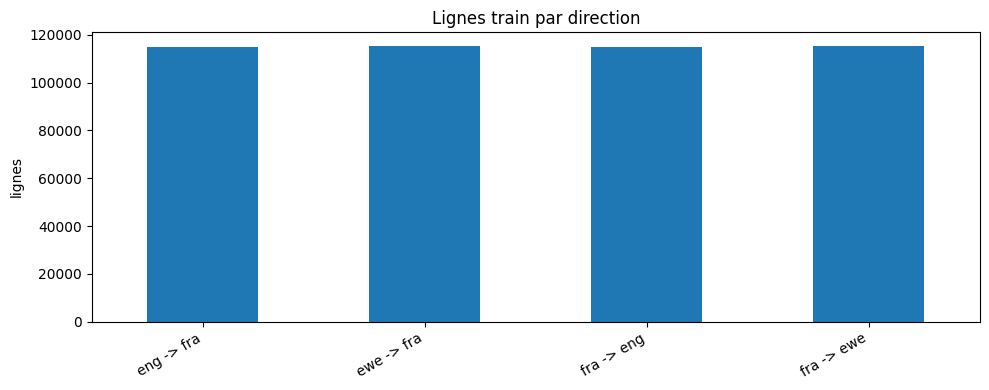

In [4]:
import pandas as pd

summary = pd.read_csv(SUMMARY_CSV)
display(summary)

religious_rows = int(summary.loc[summary["is_religious"] == True, "rows"].sum()) if (summary["is_religious"] == True).any() else 0
print("Lignes religieuses:", religious_rows)

direction_summary = summary.groupby(["split", "src_lang", "tgt_lang"], as_index=False)["rows"].sum()
display(direction_summary)

try:
    import matplotlib.pyplot as plt
    train_counts = direction_summary[direction_summary["split"] == "train"].copy()
    train_counts["direction"] = train_counts["src_lang"] + " -> " + train_counts["tgt_lang"]
    ax = train_counts.plot.bar(x="direction", y="rows", legend=False, figsize=(10, 4), title="Lignes train par direction")
    ax.set_xlabel("")
    ax.set_ylabel("lignes")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
except Exception as exc:
    print("Graphique non affiche:", exc)

## 4. Chargement des donnees pour l'entrainement

En mode `smoke`, on prend un petit echantillon. En mode `full`, on utilise tout le corpus.

In [5]:
def read_training_csv(path, max_samples=None):
    df = pd.read_csv(path)
    df["src_text"] = df["src_text"].fillna("").astype(str).str.strip()
    df["tgt_text"] = df["tgt_text"].fillna("").astype(str).str.strip()
    df = df[(df["src_text"].str.len() > 0) & (df["tgt_text"].str.len() > 0)]
    if max_samples:
        df = df.sample(n=min(max_samples, len(df)), random_state=42)
    return df.reset_index(drop=True)

train_df = read_training_csv(TRAIN_CSV, MAX_TRAIN_SAMPLES)
valid_df = read_training_csv(VALID_CSV, MAX_VALID_SAMPLES)

print("train:", len(train_df), "valid:", len(valid_df))
display(train_df[["src_lang", "tgt_lang", "src_lang_nllb", "tgt_lang_nllb", "src_text", "tgt_text", "source"]].head(8))

train: 60000 valid: 6000


,src_lang,tgt_lang,src_lang_nllb,tgt_lang_nllb,src_text,tgt_text,source
0,eng,fra,eng_Latn,fra_Latn,Don't look at this!,Ne regarde pas ça !,opus:tatoeba:v2023-04-12:en-fr
1,fra,eng,fra_Latn,eng_Latn,C'est incroyable -- Je ne sais pas comment ça ...,I -- it's unbelievable how -- I don't know how...,opus:ted2020:v1:en-fr
2,fra,eng,fra_Latn,eng_Latn,Pourquoi est-ce que tout le monde pense que je...,Why does everyone think I am stupid?,opus:tatoeba:v2023-04-12:en-fr
3,ewe,fra,ewe_Latn,fra_Latn,Menyae be fifia la ŋusẽ si gbɔagbe nu la sɔgbɔ...,Je sais qu'il y a maintenant assez de puissanc...,opus:nllb:v1:ee-fr
4,fra,eng,fra_Latn,eng_Latn,Il est économiquement irrationnel que les Grec...,"But, for the Greeks, eurozone membership does ...",opus:news-commentary:v16:en-fr
5,fra,ewe,fra_Latn,ewe_Latn,Est-ce que Jéhovah est d'accord avec ce change...,Ðe Yehowa xɔ vɔsa ma?,opus:nllb:v1:ee-fr
6,ewe,fra,ewe_Latn,fra_Latn,"14 Gawu la, esi wònye be dɔnɔ si ŋu woda gbe l...",14 Mais comme ils voyaient debout avec eux l'h...,opus:nllb:v1:ee-fr
7,ewe,fra,ewe_Latn,fra_Latn,koe yo yo Uta itami wo wo amme hane ni kae kar...,"Un sourire logea les lèvres d'Itachi, la photo...",opus:nllb:v1:ee-fr


## 5. Modele NLLB + LoRA

On charge NLLB, puis on ajoute des matrices LoRA sur les projections d'attention `q_proj` et `v_proj`.

In [6]:
from datasets import Dataset
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM, DataCollatorForSeq2Seq
from transformers import Seq2SeqTrainer, Seq2SeqTrainingArguments
from peft import LoraConfig, TaskType, get_peft_model

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
base_model = AutoModelForSeq2SeqLM.from_pretrained(MODEL_NAME)

if MODE == "full":
    base_model.gradient_checkpointing_enable()
    base_model.config.use_cache = False

lora_config = LoraConfig(
    task_type=TaskType.SEQ_2_SEQ_LM,
    r=16,
    lora_alpha=32,
    lora_dropout=0.05,
    target_modules=["q_proj", "v_proj"],
)
model = get_peft_model(base_model, lora_config)
model.print_trainable_parameters()

D:\python\traducteur-fr-en-ewe\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 512/512 [00:00<00:00, 53889.18it/s]


trainable params: 2,359,296 || all params: 617,433,088 || trainable%: 0.3821


## 6. Tokenisation NLLB multidirectionnelle

Chaque ligne porte deja `src_lang_nllb` et `tgt_lang_nllb`. Le tokenizer NLLB utilise ces codes pour injecter la bonne langue source et la bonne cible.

In [7]:
def preprocess(example):
    tokenizer.src_lang = example["src_lang_nllb"]
    tokenizer.tgt_lang = example["tgt_lang_nllb"]
    model_inputs = tokenizer(
        example["src_text"],
        max_length=MAX_SOURCE_LENGTH,
        truncation=True,
    )
    labels = tokenizer(
        text_target=example["tgt_text"],
        max_length=MAX_TARGET_LENGTH,
        truncation=True,
    )
    model_inputs["labels"] = labels["input_ids"]
    return model_inputs

train_ds = Dataset.from_pandas(train_df, preserve_index=False).map(
    preprocess,
    remove_columns=train_df.columns.tolist(),
    desc="Tokenisation train",
)
valid_ds = Dataset.from_pandas(valid_df, preserve_index=False).map(
    preprocess,
    remove_columns=valid_df.columns.tolist(),
    desc="Tokenisation valid",
)

collator = DataCollatorForSeq2Seq(tokenizer=tokenizer, model=model)
print(train_ds)
print(valid_ds)

Tokenisation valid: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 6000/6000 [00:01<00:00, 5674.84 examples/s]

Dataset({
    features: ['input_ids', 'attention_mask', 'labels'],
    num_rows: 60000
})
Dataset({
    features: ['input_ids', 'attention_mask', 'labels'],
    num_rows: 6000
})


## 7. Entrainement avec suivi des pertes

Pendant l'entrainement, le Trainer affiche `loss`, `grad_norm`, `learning_rate` et `eval_loss`. Apres la cellule, on transforme l'historique en tableau et en courbes.

In [8]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

use_bf16 = torch.cuda.is_available() and torch.cuda.is_bf16_supported()
use_fp16 = torch.cuda.is_available() and not use_bf16

eval_steps = 25 if MODE == "smoke" else 500
save_steps = 50 if MODE == "smoke" else 500
logging_steps = 5 if MODE == "smoke" else 50

training_args = Seq2SeqTrainingArguments(
    output_dir=str(OUTPUT_DIR),
    learning_rate=LEARNING_RATE,
    per_device_train_batch_size=TRAIN_BATCH_SIZE,
    per_device_eval_batch_size=EVAL_BATCH_SIZE,
    gradient_accumulation_steps=GRADIENT_ACCUMULATION_STEPS,
    num_train_epochs=EPOCHS,
    warmup_ratio=0.03,
    fp16=use_fp16,
    bf16=use_bf16,
    eval_strategy="steps",
    eval_steps=eval_steps,
    save_steps=save_steps,
    logging_steps=logging_steps,
    save_total_limit=3,
    predict_with_generate=False,
    report_to="none",
    load_best_model_at_end=False,
)

trainer = Seq2SeqTrainer(
    model=model,
    args=training_args,
    train_dataset=train_ds,
    eval_dataset=valid_ds,
    processing_class=tokenizer,
    data_collator=collator,
)

start = time.time()
train_result = trainer.train()
elapsed = time.time() - start
trainer.save_model(str(OUTPUT_DIR))
tokenizer.save_pretrained(str(OUTPUT_DIR))

print("Temps entrainement minutes:", round(elapsed / 60, 2))
print("Adapter sauvegarde dans:", OUTPUT_DIR)

[transformers] warmup_ratio is deprecated and will be removed in v5.2. Use `warmup_steps` instead.


Step,Training Loss,Validation Loss
500,6.897618,1.568894
1000,6.380122,1.532403
1500,6.328604,1.520507
2000,6.408210,1.513809
2500,6.633506,1.509291
3000,6.111765,1.506706
3500,6.517772,1.502607
4000,6.590773,1.501259
4500,7.016526,1.499109
5000,6.355492,1.497111


Temps entrainement minutes: 86.69
Adapter sauvegarde dans: D:\python\traducteur-fr-en-ewe\models\nllb-ewe-lora


## 8. Courbes et historique d'entrainement

Cette section affiche les metriques collectees pendant le fine-tuning.

,loss,grad_norm,learning_rate,epoch,step,eval_loss,eval_runtime,eval_samples_per_second,eval_steps_per_second,train_runtime,train_samples_per_second,train_steps_per_second,total_flos,train_loss
146,6.369955,1.727728,2.202062e-05,0.893333,6700,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
147,6.757164,1.334944,2.064605e-05,0.900000,6750,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
148,6.504578,1.992110,1.927148e-05,0.906667,6800,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
149,5.981458,1.478652,1.789691e-05,0.913333,6850,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
150,6.284407,1.825187,1.652234e-05,0.920000,6900,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
151,6.405985,1.450785,1.514777e-05,0.926667,6950,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
152,6.336088,1.567053,1.377320e-05,0.933333,7000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
153,NaN,NaN,NaN,0.933333,7000,1.495126,102.3825,58.604,29.302,NaN,NaN,NaN,NaN,NaN
154,6.424581,1.712378,1.239863e-05,0.940000,7050,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
155,6.632180,1.669190,1.102405e-05,0.946667,7100,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Historique sauvegarde: D:\python\traducteur-fr-en-ewe\models\nllb-ewe-lora\training_log.csv


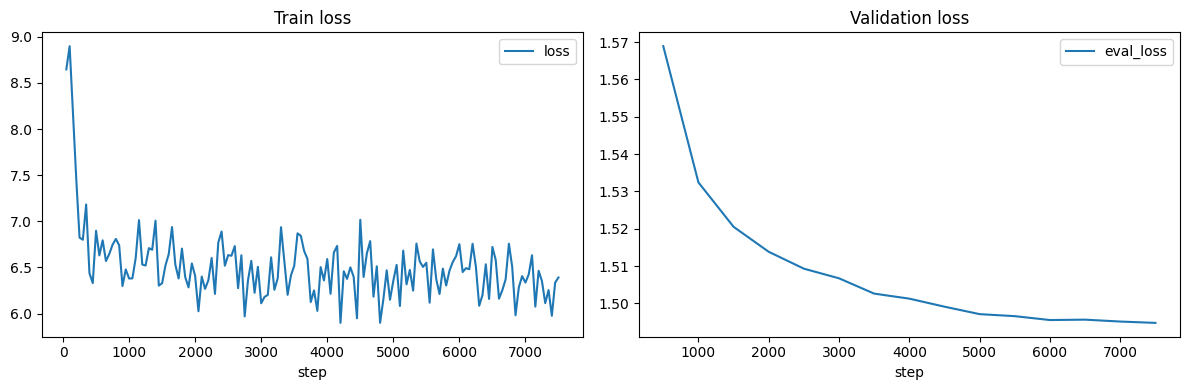

In [9]:
history = pd.DataFrame(trainer.state.log_history)
history_path = OUTPUT_DIR / "training_log.csv"
history.to_csv(history_path, index=False)
display(history.tail(20))
print("Historique sauvegarde:", history_path)

try:
    import matplotlib.pyplot as plt
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    if "loss" in history:
        history.dropna(subset=["loss"]).plot(x="step", y="loss", ax=axes[0], title="Train loss")
    if "eval_loss" in history:
        history.dropna(subset=["eval_loss"]).plot(x="step", y="eval_loss", ax=axes[1], title="Validation loss")
    plt.tight_layout()
except Exception as exc:
    print("Graphiques non affiches:", exc)

## 9. Evaluation finale BLEU / chrF

On genere des traductions sur `nllb_test.csv`, par direction, puis on calcule BLEU et chrF. Les metriques de generation sont plus lentes que `eval_loss`, donc on limite le nombre d'exemples par direction.

In [10]:
from sacrebleu import corpus_bleu, corpus_chrf

test_df = pd.read_csv(TEST_CSV)
model.eval()

def batched(values, size):
    for start_index in range(0, len(values), size):
        yield values[start_index:start_index + size]

def generate_for_group(group, batch_size=4):
    tokenizer.src_lang = group.iloc[0]["src_lang_nllb"]
    forced_bos_token_id = tokenizer.convert_tokens_to_ids(group.iloc[0]["tgt_lang_nllb"])
    predictions = []
    texts = group["src_text"].tolist()
    device = model.device
    with torch.no_grad():
        for batch in batched(texts, batch_size):
            encoded = tokenizer(
                batch,
                return_tensors="pt",
                padding=True,
                truncation=True,
                max_length=MAX_SOURCE_LENGTH,
            ).to(device)
            generated = model.generate(
                **encoded,
                forced_bos_token_id=forced_bos_token_id,
                max_new_tokens=MAX_TARGET_LENGTH,
                num_beams=4,
            )
            predictions.extend(tokenizer.batch_decode(generated, skip_special_tokens=True))
    return predictions

reports = []
examples = []
for (src_lang, tgt_lang), group in test_df.groupby(["src_lang", "tgt_lang"], sort=True):
    group = group.sample(n=min(MAX_EVAL_PER_DIRECTION, len(group)), random_state=42).reset_index(drop=True)
    predictions = generate_for_group(group, batch_size=4)
    references = group["tgt_text"].tolist()
    reports.append({
        "src_lang": src_lang,
        "tgt_lang": tgt_lang,
        "rows": len(group),
        "bleu": round(float(corpus_bleu(predictions, [references]).score), 4),
        "chrf": round(float(corpus_chrf(predictions, [references]).score), 4),
    })
    for i in range(min(5, len(group))):
        examples.append({
            "src_lang": src_lang,
            "tgt_lang": tgt_lang,
            "src_text": group.loc[i, "src_text"],
            "reference": references[i],
            "prediction": predictions[i],
        })

report_df = pd.DataFrame(reports)
examples_df = pd.DataFrame(examples)
report_path = OUTPUT_DIR / "evaluation_report.csv"
examples_path = OUTPUT_DIR / "evaluation_examples.csv"
report_df.to_csv(report_path, index=False)
examples_df.to_csv(examples_path, index=False)

display(report_df)
display(examples_df)
print("Rapport:", report_path)
print("Exemples:", examples_path)

[transformers] Both `max_new_tokens` (=128) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=128) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=128) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=128) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface

,src_lang,tgt_lang,rows,bleu,chrf
0,eng,fra,100,38.1779,64.2130
1,ewe,fra,100,17.2001,37.3819
2,fra,eng,100,42.7508,62.0198
3,fra,ewe,100,9.3312,30.3245


,src_lang,tgt_lang,src_text,reference,prediction
0,eng,fra,"So one day, I sat down to brainstorm, as you d...","Un jour, je me suis assise pour réfléchir, c'e...","Alors un jour, je me suis assise pour faire un..."
1,eng,fra,"In fact, you can buy, for 50 bucks, a stone-ag...","En fait, vous pouvez acheter, pour cinquante d...","En fait, vous pouvez acheter, pour 50 dollars,..."
2,eng,fra,How strong he is!,Comme il est fort !,Combien il est fort !
3,eng,fra,"And the answer is, these social problems are m...","Et la réponse, c'est qu'on fait face à ces pro...",Et la réponse est que ces problèmes sociaux so...
4,eng,fra,Let's hurry so that we can catch the bus.,"Dépêchons-nous, de manière à attraper le bus.",Dépêchons-nous pour pouvoir prendre le bus.
5,ewe,fra,dem Fofo la hã ŋu o.,N'oublions pas le père !,Il n'a pas non plus vu son père.
6,ewe,fra,alegrete2870 nyaa si,Le Mourmelon 282.,L'expérience de l'artisanat 2870
7,ewe,fra,18 Maxɔ Lewi viwo ɖe Israel-viwo ƒe ŋgɔgbeviwo...,"18 Or, j'ai pris les Lévites à la place de tou...",18 Je prendrai les Lévites à la place de tous ...
8,ewe,fra,Aleisha Nye,C'était Alisha.,Il s'agit d'Alice.
9,ewe,fra,Esia tae woyɔ du la be Beer-Seba va se ɖe egbe...,C'est pourquoi on a donné à la ville le nom de...,C'est pourquoi le nom de la ville est Beer-Sch...


Rapport: D:\python\traducteur-fr-en-ewe\models\nllb-ewe-lora\evaluation_report.csv
Exemples: D:\python\traducteur-fr-en-ewe\models\nllb-ewe-lora\evaluation_examples.csv


## 10. Demo de traduction

Cette cellule permet de tester rapidement l'adapter LoRA charge en memoire.

In [11]:
LANG_TO_NLLB = {"fra": "fra_Latn", "eng": "eng_Latn", "ewe": "ewe_Latn"}

def translate_text(text, source_lang="fra", target_lang="ewe", max_new_tokens=128):
    model.eval()
    tokenizer.src_lang = LANG_TO_NLLB[source_lang]
    forced_bos_token_id = tokenizer.convert_tokens_to_ids(LANG_TO_NLLB[target_lang])
    encoded = tokenizer(text, return_tensors="pt", truncation=True, max_length=MAX_SOURCE_LENGTH).to(model.device)
    with torch.no_grad():
        generated = model.generate(
            **encoded,
            forced_bos_token_id=forced_bos_token_id,
            max_new_tokens=max_new_tokens,
            num_beams=4,
        )
    return tokenizer.batch_decode(generated, skip_special_tokens=True)[0]

tests = [
    ("Bonjour, comment vas-tu ?", "fra", "ewe"),
    ("I am going to school tomorrow.", "eng", "ewe"),
    ("Je vais bien.", "fra", "eng"),
]

for text, src, tgt in tests:
    print(f"{src} -> {tgt}: {text}")
    print("=>", translate_text(text, src, tgt))
    print()

[transformers] Both `max_new_tokens` (=128) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=128) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


fra -> ewe: Bonjour, comment vas-tu ?
=> Hello, how ya doing?

eng -> ewe: I am going to school tomorrow.


[transformers] Both `max_new_tokens` (=128) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


=> Mele suku dem etsɔ.

fra -> eng: Je vais bien.
=> I'm fine.

